# 03 — Advanced modeling and optimization
Compare baseline and advanced models with chronological validation. The training workflow adds voting, walk-forward stacking and final holdout evaluation.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src' / 'wattwise').exists():
    PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))


In [2]:
import matplotlib.pyplot as plt
from wattwise.data_loader import load_data
from wattwise.preprocessing import clean_data
from wattwise.feature_engineering import make_features,chronological_split
from wattwise.model_factory import model_factory
from wattwise.evaluation import regression_metrics
df,_=clean_data(load_data()); X,y,t=make_features(df); s=chronological_split(X,y,t)
Xtr,ytr,_=s['train']; Xv,yv,_=s['validation']

In [3]:
scores={'Persistence':regression_metrics(yv,Xv.appliances_current)}
for name,m in model_factory().items():
    m.fit(Xtr,ytr); scores[name]=regression_metrics(yv,m.predict(Xv))
scores

{'Persistence': {'MAE': 25.78624914908101,
  'RMSE': 65.51310803732859,
  'R2': 0.4725535662819227,
  'n_obs': 2938},
 'Dummy mean': {'MAE': 53.66587518107392,
  'RMSE': 90.46304943362932,
  'R2': -0.0056906210836316085,
  'n_obs': 2938},
 'Ridge': {'MAE': 26.985446389653713,
  'RMSE': 58.45933186656503,
  'R2': 0.5800189952267167,
  'n_obs': 2938},
 'Random Forest': {'MAE': 27.938383483558052,
  'RMSE': 57.398075603293194,
  'R2': 0.5951290495507373,
  'n_obs': 2938},
 'Extra Trees': {'MAE': 25.77651929426319,
  'RMSE': 55.983397433927905,
  'R2': 0.6148406414902783,
  'n_obs': 2938},
 'HistGradientBoosting': {'MAE': 22.121437151803608,
  'RMSE': 57.32450949622646,
  'R2': 0.5961662164613408,
  'n_obs': 2938},
 'HistGradientBoosting (squared loss)': {'MAE': 24.6504711638457,
  'RMSE': 55.068862997312706,
  'R2': 0.627321642535215,
  'n_obs': 2938},
 'XGBoost': {'MAE': 22.335276740679863,
  'RMSE': 55.860275365418076,
  'R2': 0.6165329100146977,
  'n_obs': 2938}}

In [4]:
from wattwise.optimization import optimize
tuned,search=optimize(Xtr,ytr,trials=5)
search,regression_metrics(yv,tuned.predict(Xv))

[I 2026-10-23 01:40:33,112] A new study created in memory with name: no-name-e7897dd7-c459-4113-9c12-fb3ce7194b3f


[I 2026-10-23 01:40:34,588] Trial 0 finished with value: 26.906718088233827 and parameters: {'max_iter': 125, 'learning_rate': 0.09339573747495579, 'max_leaf_nodes': 25, 'min_samples_leaf': 56, 'l2_regularization': 0.22856175997064762}. Best is trial 0 with value: 26.906718088233827.


[I 2026-10-23 01:40:36,140] Trial 1 finished with value: 27.920844634641696 and parameters: {'max_iter': 98, 'learning_rate': 0.027096289749237643, 'max_leaf_nodes': 28, 'min_samples_leaf': 56, 'l2_regularization': 4.258888210290081}. Best is trial 0 with value: 26.906718088233827.


[I 2026-10-23 01:40:37,309] Trial 2 finished with value: 27.013248761643712 and parameters: {'max_iter': 82, 'learning_rate': 0.09591442461979317, 'max_leaf_nodes': 27, 'min_samples_leaf': 32, 'l2_regularization': 0.2620503255096255}. Best is trial 0 with value: 26.906718088233827.


[I 2026-10-23 01:40:38,441] Trial 3 finished with value: 27.106083110749797 and parameters: {'max_iter': 102, 'learning_rate': 0.03811641886708834, 'max_leaf_nodes': 20, 'min_samples_leaf': 46, 'l2_regularization': 0.4678719265016201}. Best is trial 0 with value: 26.906718088233827.


[I 2026-10-23 01:40:39,794] Trial 4 finished with value: 27.12533024589061 and parameters: {'max_iter': 154, 'learning_rate': 0.03033358083772739, 'max_leaf_nodes': 14, 'min_samples_leaf': 42, 'l2_regularization': 1.120548642504815}. Best is trial 0 with value: 26.906718088233827.


({'best_params': {'max_iter': 125,
   'learning_rate': 0.09339573747495579,
   'max_leaf_nodes': 25,
   'min_samples_leaf': 56,
   'l2_regularization': 0.22856175997064762},
  'best_cv_mae': 26.906718088233827,
  'trials': 5,
  'backend': 'Optuna',
  'objective': 'mean MAE over 3 expanding TimeSeriesSplit folds within training data',
  'seed': 42,
  'n_splits': 3,
  'history': [{'number': 0,
    'value': 26.906718088233827,
    'params': {'max_iter': 125,
     'learning_rate': 0.09339573747495579,
     'max_leaf_nodes': 25,
     'min_samples_leaf': 56,
     'l2_regularization': 0.22856175997064762},
    'state': 'TrialState.COMPLETE'},
   {'number': 1,
    'value': 27.920844634641696,
    'params': {'max_iter': 98,
     'learning_rate': 0.027096289749237643,
     'max_leaf_nodes': 28,
     'min_samples_leaf': 56,
     'l2_regularization': 4.258888210290081},
    'state': 'TrialState.COMPLETE'},
   {'number': 2,
    'value': 27.013248761643712,
    'params': {'max_iter': 82,
     'learn

In [5]:
import pandas as pd
from pathlib import Path
p=Path('reports/model_comparison.csv')
pd.read_csv(p) if p.exists() else 'Run python -m wattwise.train to generate the actual comparison.'

,model,split,MAE,RMSE,R2,MAE_std,CV_MAE,CV_MAE_std,CV_RMSE,CV_RMSE_std,...,n_folds,mean_fold_n_obs,CV_protocol,CV_status,n_obs,components,selected,run_id,dataset_fingerprint,target_horizon_rows
0,Persistence,training_cv,30.387009,73.218954,0.480185,1.020913,30.387009,1.020913,73.218954,1.492876,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
1,Dummy mean,training_cv,60.098526,101.742530,-0.000858,1.274671,60.098526,1.274671,101.742530,4.453711,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
2,Ridge,training_cv,36.608450,69.480426,0.527166,8.037521,36.608450,8.037521,69.480426,2.313514,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
3,Random Forest,training_cv,31.720463,64.880462,0.589735,1.812246,31.720463,1.812246,64.880462,0.727758,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
4,Extra Trees,training_cv,30.113344,64.122317,0.599721,1.906778,30.113344,1.906778,64.122317,0.348071,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
5,HistGradientBoosting,training_cv,27.048853,67.234082,0.561381,1.022492,27.048853,1.022492,67.234082,1.177408,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
6,HistGradientBoosting (squared loss),training_cv,29.386172,64.940858,0.587873,2.179476,29.386172,2.179476,64.940858,1.545935,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
7,XGBoost,training_cv,27.083455,65.272756,0.586042,1.460533,27.083455,1.460533,65.272756,0.642621,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
8,Tuned HistGradientBoosting,training_cv,27.093277,67.307595,0.560312,1.159457,27.093277,1.159457,67.307595,1.295858,...,3.0,3428.0,nested temporal CV: 3 outer expanding folds; e...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
9,Persistence,validation,25.786249,65.513108,0.472554,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,2938.0,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1


## Conclusion
Use only generated validation/test artifacts for claims. The final test set is not used to tune parameters or select the model.

## Baseline and advanced model table

All individual estimators below use the same training and validation periods. Persistence uses Appliances at time *t* to predict the next interval.

In [6]:
score_table=pd.DataFrame([{'model':k,**v} for k,v in scores.items()]).sort_values('MAE')
score_table


,model,MAE,RMSE,R2,n_obs
5,HistGradientBoosting,22.121437,57.324509,0.596166,2938
7,XGBoost,22.335277,55.860275,0.616533,2938
6,HistGradientBoosting (squared loss),24.650471,55.068863,0.627322,2938
4,Extra Trees,25.776519,55.983397,0.614841,2938
0,Persistence,25.786249,65.513108,0.472554,2938
2,Ridge,26.985446,58.459332,0.580019,2938
3,Random Forest,27.938383,57.398076,0.595129,2938
1,Dummy mean,53.665875,90.463049,-0.005691,2938


### Compare validation errors

MAE is easy to interpret in Wh per 10-minute interval. RMSE gives greater weight to large misses. R² may be negative if a model is worse than predicting the validation mean.

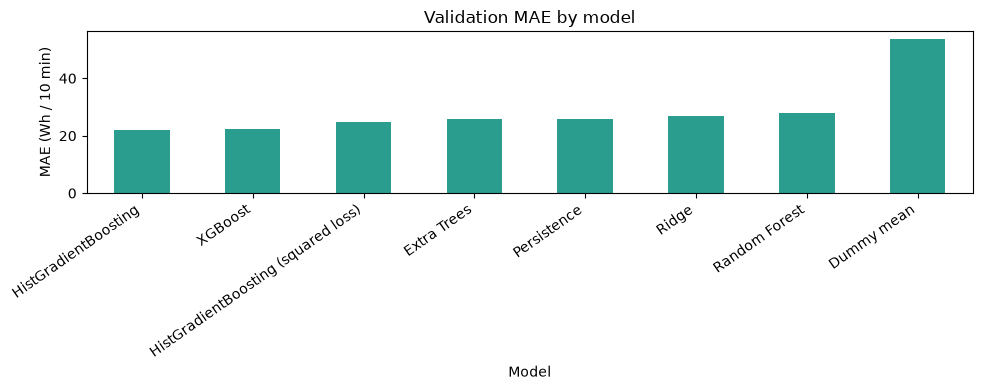

In [7]:
fig,ax=plt.subplots(figsize=(10,4)); score_table.plot.bar(x='model',y='MAE',legend=False,ax=ax,color='#2a9d8f'); ax.set(title='Validation MAE by model',xlabel='Model',ylabel='MAE (Wh / 10 min)'); plt.xticks(rotation=35,ha='right'); plt.tight_layout()


## Expanding-window validation

The time-series CV folds preserve order: each validation fold comes after its training fold. Base models use three expanding folds within training history and report means and population standard deviations. Tuned HistGradientBoosting uses nested temporal CV: each of three outer folds is tuned independently using three inner folds. Voting and stacking are assembled on validation and are not given a potentially biased training-CV score. Validation selects the model; the final test is not involved.

In [8]:
from wattwise.evaluation import temporal_cv_summary
cv_summary=temporal_cv_summary(model_factory()['Ridge'],Xtr,ytr,n_splits=3)
cv_summary

{'CV_MAE': 36.60845000714759,
 'CV_MAE_std': 8.03752128691261,
 'CV_RMSE': 69.48042578460722,
 'CV_RMSE_std': 2.3135142256777104,
 'CV_R2': 0.5271664095377138,
 'CV_R2_std': 0.07470619027701622,
 'CV_R2_valid_folds': 3,
 'n_folds': 3,
 'mean_fold_n_obs': 3428.0,
 'folds': [{'fold': 1,
   'MAE': 47.68678870152974,
   'RMSE': 72.56377604903288,
   'R2': 0.42583097647730106,
   'n_obs': 3428,
   'train_end_index': 3428,
   'validation_start_index': 3429,
   'R2_status': 'valid'},
  {'fold': 2,
   'MAE': 33.27278502477552,
   'RMSE': 68.88650350455012,
   'R2': 0.5519522829457122,
   'n_obs': 3428,
   'train_end_index': 6856,
   'validation_start_index': 6857,
   'R2_status': 'valid'},
  {'fold': 3,
   'MAE': 28.865776295137515,
   'RMSE': 66.99099780023865,
   'R2': 0.6037159691901282,
   'n_obs': 3428,
   'train_end_index': 10284,
   'validation_start_index': 10285,
   'R2_status': 'valid'}]}

## Hyperparameter search results

Optuna optimizes mean MAE over three expanding folds on training history. The nested CV results estimate tuned-model performance on outer folds; Optuna’s best inner-fold value is a tuning score, not an independent estimate. Validation is a separate model-selection block and test values never influence tuning.

In [9]:
search


{'best_params': {'max_iter': 125,
  'learning_rate': 0.09339573747495579,
  'max_leaf_nodes': 25,
  'min_samples_leaf': 56,
  'l2_regularization': 0.22856175997064762},
 'best_cv_mae': 26.906718088233827,
 'trials': 5,
 'backend': 'Optuna',
 'objective': 'mean MAE over 3 expanding TimeSeriesSplit folds within training data',
 'seed': 42,
 'n_splits': 3,
 'history': [{'number': 0,
   'value': 26.906718088233827,
   'params': {'max_iter': 125,
    'learning_rate': 0.09339573747495579,
    'max_leaf_nodes': 25,
    'min_samples_leaf': 56,
    'l2_regularization': 0.22856175997064762},
   'state': 'TrialState.COMPLETE'},
  {'number': 1,
   'value': 27.920844634641696,
   'params': {'max_iter': 98,
    'learning_rate': 0.027096289749237643,
    'max_leaf_nodes': 28,
    'min_samples_leaf': 56,
    'l2_regularization': 4.258888210290081},
   'state': 'TrialState.COMPLETE'},
  {'number': 2,
   'value': 27.013248761643712,
   'params': {'max_iter': 82,
    'learning_rate': 0.09591442461979317,

## Ensemble and feature ablation evidence

The training command builds equal-weight top-three voting using validation MAE and a walk-forward stack where each meta-training prediction comes from a base model trained on earlier rows. All candidates are refit on the same train-plus-validation history before final test comparison. Feature ablation compares all features, no lag/rolling consumption history, and training-only mutual-information top 20.

In [10]:
from pathlib import Path
import pandas as pd
comparison=Path('reports/model_comparison.csv')
print('Saved model comparison:'); display(pd.read_csv(comparison) if comparison.exists() else 'Run training first.')
print('Train/validation feature ablation:'); display(pd.read_csv('reports/metrics/feature_ablation.csv') if Path('reports/metrics/feature_ablation.csv').exists() else 'Run training first.')


Saved model comparison:


,model,split,MAE,RMSE,R2,MAE_std,CV_MAE,CV_MAE_std,CV_RMSE,CV_RMSE_std,...,n_folds,mean_fold_n_obs,CV_protocol,CV_status,n_obs,components,selected,run_id,dataset_fingerprint,target_horizon_rows
0,Persistence,training_cv,30.387009,73.218954,0.480185,1.020913,30.387009,1.020913,73.218954,1.492876,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
1,Dummy mean,training_cv,60.098526,101.742530,-0.000858,1.274671,60.098526,1.274671,101.742530,4.453711,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
2,Ridge,training_cv,36.608450,69.480426,0.527166,8.037521,36.608450,8.037521,69.480426,2.313514,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
3,Random Forest,training_cv,31.720463,64.880462,0.589735,1.812246,31.720463,1.812246,64.880462,0.727758,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
4,Extra Trees,training_cv,30.113344,64.122317,0.599721,1.906778,30.113344,1.906778,64.122317,0.348071,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
5,HistGradientBoosting,training_cv,27.048853,67.234082,0.561381,1.022492,27.048853,1.022492,67.234082,1.177408,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
6,HistGradientBoosting (squared loss),training_cv,29.386172,64.940858,0.587873,2.179476,29.386172,2.179476,64.940858,1.545935,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
7,XGBoost,training_cv,27.083455,65.272756,0.586042,1.460533,27.083455,1.460533,65.272756,0.642621,...,3.0,3428.0,3-fold expanding TimeSeriesSplit on training b...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
8,Tuned HistGradientBoosting,training_cv,27.093277,67.307595,0.560312,1.159457,27.093277,1.159457,67.307595,1.295858,...,3.0,3428.0,nested temporal CV: 3 outer expanding folds; e...,valid,NaN,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1
9,Persistence,validation,25.786249,65.513108,0.472554,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,2938.0,NaN,NaN,55004ee9-e3d3-433c-9528-6e2227d2b7d8,4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e...,1


Train/validation feature ablation:


,feature_set,feature_count,MAE,RMSE,R2,n_obs,run_id
0,all_features,63,22.121437,57.324509,0.596166,2938,55004ee9-e3d3-433c-9528-6e2227d2b7d8
1,without_consumption_history,49,22.265324,57.473067,0.594070,2938,55004ee9-e3d3-433c-9528-6e2227d2b7d8
2,mutual_information_top_20,20,22.012251,57.263843,0.597021,2938,55004ee9-e3d3-433c-9528-6e2227d2b7d8


## Final held-out test results

Only after validation selection is complete is the selected model scored on the final period. Read saved artifacts to report actual run outputs; do not use these numbers to revise model selection.

In [11]:
from pathlib import Path
import json
metric_path=Path('reports/metrics/final_metrics.json')
json.loads(metric_path.read_text()) if metric_path.exists() else 'Run python -m wattwise.train to create the final test evaluation.'


{'run_id': '55004ee9-e3d3-433c-9528-6e2227d2b7d8',
 'dataset_fingerprint': '4b5099e7dbc3057d81a1ea1ccd7ad20b074aa7226dc51e62b113dd3edc357f41',
 'selected_model': 'Voting (top 3)',
 'selection': {'selected_model': 'Voting (top 3)',
  'metric': 'validation MAE',
  'score': 21.93873222087764,
  'tie_breaking': ['lower validation MAE',
   'then lower validation RMSE',
   'then model name ascending'],
  'rationale': 'Minimum validation MAE among the declared candidates; the held-out test was not used for selection.',
  'validation_candidates': ['Persistence',
   'Dummy mean',
   'Ridge',
   'Random Forest',
   'Extra Trees',
   'HistGradientBoosting',
   'HistGradientBoosting (squared loss)',
   'XGBoost',
   'Tuned HistGradientBoosting',
   'Voting (top 3)',
   'Temporal Stacking'],
  'voting_components': ['Tuned HistGradientBoosting',
   'HistGradientBoosting',
   'XGBoost'],
  'voting_weights': {'Tuned HistGradientBoosting': 0.3333333333333333,
   'HistGradientBoosting': 0.33333333333333

## Modeling conclusions

Identify the validation-selected model, compare it to persistence, and discuss any validation-to-test performance change. Include runtime/dependency considerations and the risk of overfitting a single-house period.

In [12]:
import json
from pathlib import Path
final=json.loads(Path('reports/metrics/final_metrics.json').read_text())
print('Selected using validation:',final['selection']['selected_model'])
print('Selection rule:',final['selection']['metric'],'=',round(final['selection']['score'],3),'Wh')
print('Held-out metrics (reported after selection):',final['test'])

Selected using validation: Voting (top 3)
Selection rule: validation MAE = 21.939 Wh
Held-out metrics (reported after selection): {'MAE': 22.3854587786086, 'RMSE': 58.72306663971104, 'R2': 0.5833419624023941, 'n_obs': 2939}
